In [37]:
import os
import sys

# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [38]:
import os
import os.path as op
from functools import partial

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, average_dipoles
from hnn_core.optimization import Optimizer, add_opt_drives, set_params_opt_drives
from hnn_core.dipole import _corr, _rmse, _rmse_corr
import numpy as np

import pickle
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from scipy.stats import pearsonr

pathfig = os.path.join(os.getcwd(), 'figures')
pathgen = '/users/kduecker/hnn-data/'

n_procs = 1

In [39]:
with open(f'opt_ERP_cma_strict_constraints.pkl', 'rb') as file:
        optim =  pickle.load(file)

In [40]:
optim.obj_

[np.float64(39.18707768370237)]

In [41]:
data_url = f'{pathgen}MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

tstop = exp_dpl.times[-1]
scaling_factor = 1000
smooth_win = 5

In [42]:
0.8954115179806736

dist1 -> L5_pyramidal
cell counts: 100 srcs, 100 targets
connection probability: 1.0 
loc: 'distal'; receptor: 'nmda'
weight: 0.6261677627861055; delay: 0.1; lamtha: 3.0threshold: 0.0gain: 1.0
 

{'L2_basket': np.float64(0.2415291110178448),
 'L2_pyramidal': np.float64(0.2841410220540285),
 'L5_basket': np.float64(0.36777276759270106),
 'L5_pyramidal': np.float64(0.8954115179806736)}

In [45]:
optim.net_.connectivity

[L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_basket -> L2_pyramidal
 cell counts: 35 srcs, 100 targets
 connection probability: 1.0 
 loc: 'soma'; receptor: 'gabaa'
 weight: 0.2; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_b

In [51]:
10**np.log10(1e-15)

np.float64(1e-15)

In [49]:
optim.net_.external_drives['prox1']['weights_ampa']

{'L2_basket': np.float64(0.14800001192802212),
 'L2_pyramidal': np.float64(0.3521630454111331),
 'L5_basket': np.float64(0.10928153842760834),
 'L5_pyramidal': np.float64(0.07710713382467138)}

In [11]:
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=5, bsl_cor="duecker")

MPIBackend is set to use 1 core: transferring the simulation to JoblibBackend....
Joblib will run 5 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Building the NEURON model
[Done]
Trial 2: 0.03 ms...
Trial 2: 10.0 ms...
Trial 2: 20.0 ms...
Trial 2: 30.0 ms...
Trial 2: 40.0 ms...
Trial 2: 50.0 ms...
Trial 2: 60.0 ms...
Trial 2: 70.0 ms...
Trial 2: 80.0 ms...
Trial 2: 90.0 ms...
Trial 2: 100.0 ms...
Trial 2: 110.0 ms...
Trial 2: 120.0 ms...
Trial 2: 130.0 ms...
Trial 2: 14

In [12]:
optim.opt_params_

array([6.34081357e-01, 1.83561539e-01, 3.95117664e-02, 1.59260866e-05,
       1.38858997e-02, 2.59479681e-01, 5.45647007e-01, 4.01831006e-02,
       1.28538415e-01, 9.54001697e-01, 4.07196690e-01, 2.26689251e-02,
       9.80411413e-02, 1.49179461e-01, 4.07410333e-01, 5.10349300e-01,
       2.96866399e-01, 3.86891960e-01, 5.55236101e-01, 7.07289012e-01,
       1.20521770e-02, 9.17283576e-01, 2.00053742e+01, 6.00705101e+00,
       1.04837815e+00, 6.19912268e+01, 6.98009196e+00, 1.67962948e+00,
       9.49883523e+01, 9.97471218e+00, 1.00185026e+00])

In [13]:
optim.net_.external_drives

{'prox1': <External drive 'prox1'
 drive class: evoked
 target location: proximal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
 number of drive cells: 270
 cell-specific: True
 dynamic parameters:
 	mu: 20.005374232237248
 	sigma: 6.007051009694463
 	numspikes: 1
 event times instantiated for 5 trials>,
 'prox2': <External drive 'prox2'
 drive class: evoked
 target location: proximal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
 number of drive cells: 270
 cell-specific: True
 dynamic parameters:
 	mu: 94.98835230750782
 	sigma: 9.974712183428206
 	numspikes: 1
 event times instantiated for 5 trials>,
 'dist1': <External drive 'dist1'
 drive class: evoked
 target location: distal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_pyramidal']
 number of drive cells: 235
 cell-specific: True
 dynamic parameters:
 	mu: 61.991226845399666
 	sigma: 6.980091956542597
 	numspikes: 1
 event times instantiated for 5 trials>}

In [14]:
dpl[0].data['agg']

array([0.        , 0.00017916, 0.00014187, ..., 0.07917825, 0.07920987,
       0.07924073], shape=(6934,))

In [15]:
dpl = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl]
avg_dpl = average_dipoles(dpl)

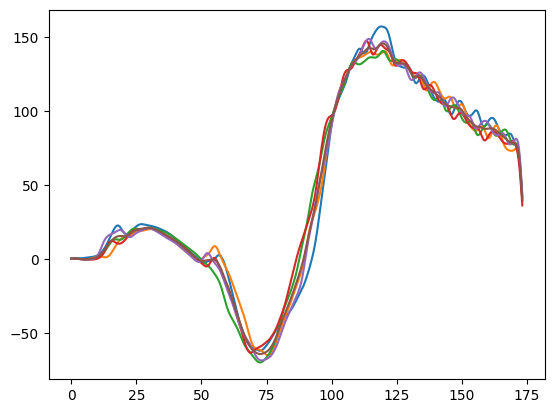

In [16]:
#plt.plot(exp_dpl.times, exp_dpl.data['agg'])
for d in dpl:
    plt.plot(d.times, d.data['agg'])
plt.plot(avg_dpl.times, avg_dpl.data['agg'])

In [13]:
_rmse_corr(avg_dpl, exp_dpl, tstop=tstop)

np.float64(nan)